# 07 — Metadata góc tới và hiệu chuẩn Sentinel-1 thật

Nhánh bổ sung, không thay đổi mô hình SOS. Tile 1.024×1.024 có DN uint16,
góc tới và LUT hiệu chuẩn từ cùng cảnh gốc. Chưa có nhãn dầu cho tile này.
Không dùng kết quả này thay Precision/Recall/F1 trên dữ liệu có nhãn.

Chuẩn bị từ thư mục gốc:
```text
python scripts/physical/fetch_sentinel_metadata.py
python scripts/physical/fetch_sentinel_window.py
python scripts/physical/fetch_scene_wind.py
```
Chỉ đọc cửa sổ nhỏ qua HTTP Range, không tải toàn cảnh 626 MB.
Nguồn và hash: `docs/management/sentinel_window_audit.json`.


In [1]:
from pathlib import Path
import sys, json, inspect
from IPython.display import display, Code, Image, Markdown
ROOT=next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'src/sar_oil').is_dir())
sys.path.insert(0,str(ROOT))
from scripts.physical.sentinel_calibration_demo import bilinear_numpy, main
display(Code(inspect.getsource(bilinear_numpy),language='python'))

def bilinear_numpy(y, x, values, rows, cols):
    """Bilinear interpolation on a nonuniform rectilinear grid; no extrapolation."""
    y, x, values = np.asarray(y), np.asarray(x), np.asarray(values)
    rows, cols = np.asarray(rows), np.asarray(cols)
    if values.shape != (len(y), len(x)) or np.any(np.diff(y)<=0) or np.any(np.diff(x)<=0):
        raise ValueError('Invalid interpolation grid')
    if rows.min()<y[0] or rows.max()>y[-1] or cols.min()<x[0] or cols.max()>x[-1]:
        raise ValueError('Extrapolation is not allowed')
    iy = np.clip(np.searchsorted(y,rows,side='right')-1,0,len(y)-2)
    ix = np.clip(np.searchsorted(x,cols,side='right')-1,0,len(x)-2)
    wy = ((rows-y[iy])/(y[iy+1]-y[iy]))[:,None]
    wx = ((cols-x[ix])/(x[ix+1]-x[ix]))[None,:]
    top = values[iy[:,None],ix[None,:]]*(1-wx)+values[iy[:,None],ix[None,:]+1]*wx
    bottom = values[iy[:,None]+1,ix[None,:]]*(1-wx)+values[iy[:,None]+1,ix[None,:]+1]*wx
    return top*(1-wy)+bottom*wy

## Công thức và phép đối chứng

`backscatter = DN² / LUT²`, theo ESA L1 Detailed Algorithm Definition,
công thức 9-53–9-56. Nội suy song tuyến tính NumPy được đối chiếu với
SciPy RegularGridInterpolator trên toàn bộ tile, cùng lưới và cùng biên.
LUT gamma chứa yếu tố hình học góc tới ellipsoid; không đồng nghĩa đã loại
hết ảnh hưởng góc/gió lên tán xạ mặt biển. Xem nguồn đầy đủ trong
`results/physical/README.md`.

Ô dưới thực sự chạy lại hiệu chuẩn và lưu JSON/mảng/biểu đồ; không chỉ đọc số có sẵn.

{
  "checks": {
    "incidence_interpolation": {
      "max_abs": 2.1316282072803006e-14,
      "mse": 2.3268555957351877e-29
    },
    "sigmaNought_lut_interpolation": {
      "max_abs": 3.410605131648481e-13,
      "mse": 4.54662447914459e-27
    },
    "sigmaNought_calibrated": {
      "max_abs": 5.329070518200751e-15,
      "mse": 5.097690817972775e-34
    },
    "gamma_lut_interpolation": {
      "max_abs": 3.410605131648481e-13,
      "mse": 3.5526104347595385e-27
    },
    "gamma_calibrated": {
      "max_abs": 1.4210854715202004e-14,
      "mse": 1.0336860872038874e-33
    }
  },
  "angle_range": [
    38.62887385883345,
    39.24549190619312
  ],
  "gamma_relation_max_abs_db": 0.0033069978644294003
}


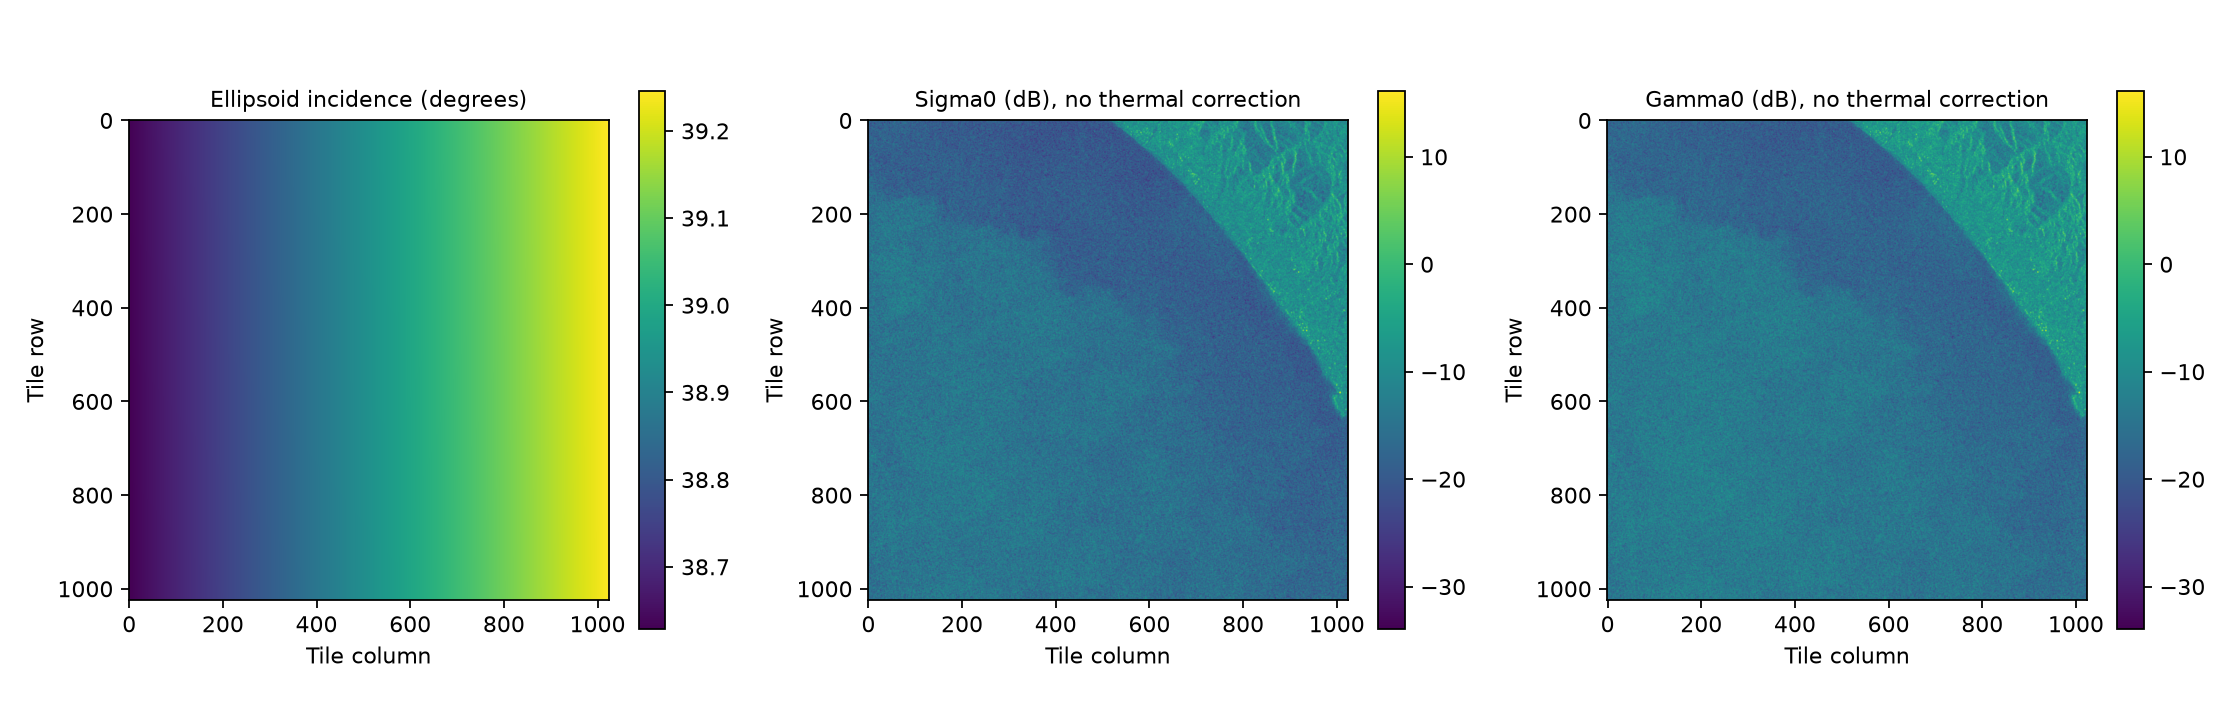

In [2]:
main()
result=json.loads((ROOT/'results/physical/calibration.json').read_text())
assert result['allclose_passed']
display(Image(filename=str(ROOT/'results/physical/calibration.png')))

## Giới hạn phải ghi trong báo cáo

- Cả source và demo chưa trừ nhiễu nhiệt.
- Gió ERA5 ghép tại tâm tile là dữ liệu ô lưới thô; chưa có nhãn dầu trên tile.
- Chưa xác nhận ánh xạ tile tới patch JPEG DARTIS hoặc SOS.
- Sai số NumPy–SciPy nhỏ kiểm chứng tính toán, chưa chứng minh gamma tăng F1.
- Chưa đối chiếu toàn bộ với bộ xử lý SAR độc lập như SNAP.


## Gió ERA5 tại tâm tile

Chọn rõ ERA5, ô lưới gần nhất và tắt downscaling theo độ cao. Nội suy hai
vector u/v tại hai giờ kề thời điểm chụp, không lấy trung bình góc hướng gió.
Đây là gió tái phân tích, không phải đo hiện trường hoặc gió từng pixel SAR.
Nguồn: [Open-Meteo Historical API](https://open-meteo.com/en/docs/historical-weather-api).


SAR time UTC: 2019-01-05T15:49:14.737876+00:00
ERA5 nearest grid: [35.0, 32.5] distance km: 13.622
Interpolated wind m/s: 3.3454 FROM degrees: 261.41


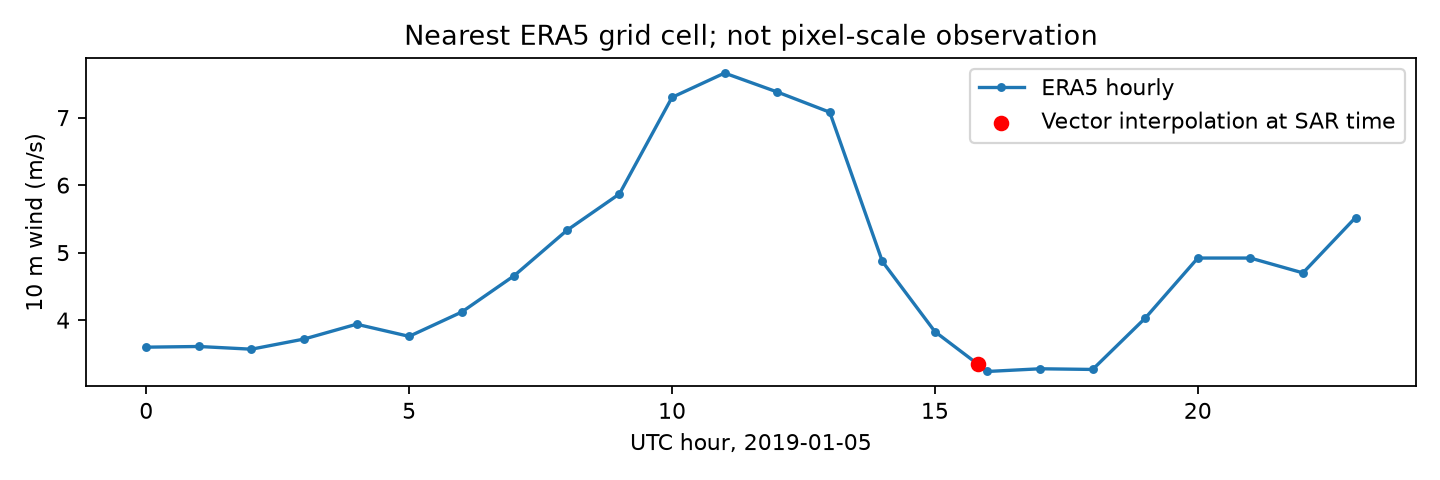

In [3]:
import hashlib
import matplotlib.pyplot as plt
from datetime import datetime
wind=json.loads((ROOT/'results/physical/wind.json').read_text())
raw_path=ROOT/wind['raw_file']
assert hashlib.sha256(raw_path.read_bytes()).hexdigest()==wind['raw_sha256']
assert wind['scene']==result['scene']
assert wind['annotation_sha256']==next(r['sha256'] for r in result['metadata_files'] if r.get('file','').endswith('/annotation/iw-vv.xml'))
raw=json.loads(raw_path.read_text())
print('SAR time UTC:', wind['sar_center_utc'])
print('ERA5 nearest grid:', wind['returned_grid_lat_lon'], 'distance km:', round(wind['grid_center_distance_km'],3))
print('Interpolated wind m/s:', round(wind['speed_m_s'],4), 'FROM degrees:', round(wind['from_degrees'],3))
fig,ax=plt.subplots(figsize=(9,3))
hours=[datetime.fromisoformat(t).hour for t in raw['hourly']['time']]
ax.plot(hours,raw['hourly']['wind_speed_10m'],marker='.',label='ERA5 hourly')
moment=datetime.fromisoformat(wind['sar_center_utc'])
hour=moment.hour+moment.minute/60+moment.second/3600
ax.scatter([hour],[wind['speed_m_s']],color='red',label='Vector interpolation at SAR time',zorder=3)
ax.set(xlabel='UTC hour, 2019-01-05',ylabel='10 m wind (m/s)',title='Nearest ERA5 grid cell; not pixel-scale observation')
ax.legend(); fig.tight_layout()
plot_path=ROOT/'results/physical/wind.png'
fig.savefig(plot_path,dpi=160); plt.close(fig)
display(Image(filename=str(plot_path)))